# 02 — EDA de los datasets

Análisis exploratorio de **Real Life Violence Situations** (y de **RWF-2000**
cuando su carpeta está disponible en la máquina). Responde, antes de entrenar:

1. ¿Cuántos videos hay por clase y están todos sanos?
2. ¿Qué duración, fps y resolución tienen? ¿Son uniformes?
3. ¿Hay diferencias entre clases que el modelo pueda aprender por error
   (atajos) en vez de aprender el comportamiento?

Los metadatos se leen con `src/preprocessing/dataset_metadata.py` (solo
cabeceras de video, no se decodifica el clip completo).

**Rutas esperadas** (la carpeta `data/raw/` no se versiona; ver `data/README.md`):

- `data/raw/real_life/{Violence,NonViolence}/`
- `data/raw/rwf2000/{train,val}/{Train_Fight,Train_NonFight,Val_Fight,Val_NonFight}/`

## 1. Imports y configuración

In [1]:
import sys
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# El notebook vive en notebooks/, asi que la raiz del repo es el padre.
ROOT = Path("..").resolve()
sys.path.insert(0, str(ROOT))

from src.preprocessing.dataset_metadata import scan_dataset

REAL_LIFE_DIR = ROOT / "data" / "raw" / "real_life"
RWF_DIR = ROOT / "data" / "raw" / "rwf2000"
CACHE_DIR = ROOT / "data" / "processed"  # ignorada por git
CACHE_DIR.mkdir(parents=True, exist_ok=True)

# Colores fijos por clase para que todas las figuras sean consistentes.
COLORES = {"violencia": "#d1495b", "no_violencia": "#2e86ab"}
plt.rcParams.update({"figure.dpi": 90, "axes.spines.top": False, "axes.spines.right": False})

## 2. Carga de metadatos

Escanear 2000 videos tarda ~25 s, así que el resultado se guarda en un CSV en
`data/processed/` (no versionado) y se reutiliza. Borrar el CSV fuerza un
nuevo escaneo.

In [2]:
def cargar(nombre: str, carpeta: Path) -> pd.DataFrame:
    """Devuelve los metadatos de un dataset, usando cache en CSV si existe."""
    if not carpeta.exists():
        print(f"[{nombre}] carpeta no encontrada: {carpeta.relative_to(ROOT)} -> se omite")
        return pd.DataFrame()
    cache = CACHE_DIR / f"metadata_{nombre}.csv"
    if cache.exists():
        return pd.read_csv(cache, keep_default_na=False)
    df = scan_dataset(carpeta, nombre)
    df.to_csv(cache, index=False)
    return df


real = cargar("real_life", REAL_LIFE_DIR)
rwf = cargar("rwf2000", RWF_DIR)
meta = pd.concat([d for d in (real, rwf) if len(d)], ignore_index=True)
print(meta.groupby("dataset").size().to_string())
# La columna "ruta" (ruta absoluta local) no se muestra para no filtrarla
# en la salida del notebook que se sube al repo.
meta.drop(columns="ruta").head()

[rwf2000] carpeta no encontrada: data\raw\rwf2000 -> se omite
dataset
real_life    2000


,dataset,split,clase,archivo,formato,bytes,frames,fps,ancho,alto,legible,segundos
0,real_life,,no_violencia,NV_1.mp4,mp4,7982710,66,24.900440,1920,1080,True,2.650556
1,real_life,,no_violencia,NV_10.mp4,mp4,1151518,150,30.000000,224,224,True,5.000000
2,real_life,,no_violencia,NV_100.mp4,mp4,1588682,150,30.000000,224,224,True,5.000000
3,real_life,,no_violencia,NV_1000.mp4,mp4,519064,104,23.976024,1280,720,True,4.337667
4,real_life,,no_violencia,NV_101.mp4,mp4,1021964,150,30.000000,224,224,True,5.000000


## 3. Integridad y distribución de clases

Si hubiera clases muy desbalanceadas habría que ponderar la pérdida o
usar métricas por clase; por eso se mira antes de entrenar.

Ilegibles: 0
Con 0 bytes: 0
clase      no_violencia  violencia
dataset                           
real_life          1000       1000


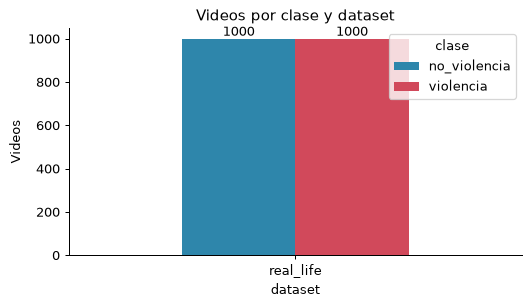

In [3]:
# Videos que OpenCV no logra leer (deberian ser 0).
print("Ilegibles:", int((~meta["legible"].astype(bool)).sum()))
print("Con 0 bytes:", int((meta["bytes"] == 0).sum()))

conteo = meta.groupby(["dataset", "clase"]).size().unstack(fill_value=0)
print(conteo.to_string())

fig, ax = plt.subplots(figsize=(6, 3.5))
conteo.plot.bar(ax=ax, color=[COLORES[c] for c in conteo.columns], rot=0)
ax.set_ylabel("Videos")
ax.set_title("Videos por clase y dataset")
for cont in ax.containers:
    ax.bar_label(cont)
plt.tight_layout()
plt.show()

## 4. Duración de los clips

El pipeline toma 16 frames **espaciados uniformemente** de todo el clip. En un clip
de 5 s eso es un frame cada ~0,33 s, pero en uno de varios minutos cada frame
quedaría a decenas de segundos del anterior y el movimiento corto se perdería.

                         count  mean    std  min  50%   95%     max
dataset   clase                                                    
real_life no_violencia  1000.0   5.1   5.55  1.0  5.0  5.34  179.90
          violencia     1000.0   5.4  12.46  2.9  5.0  5.90  375.73


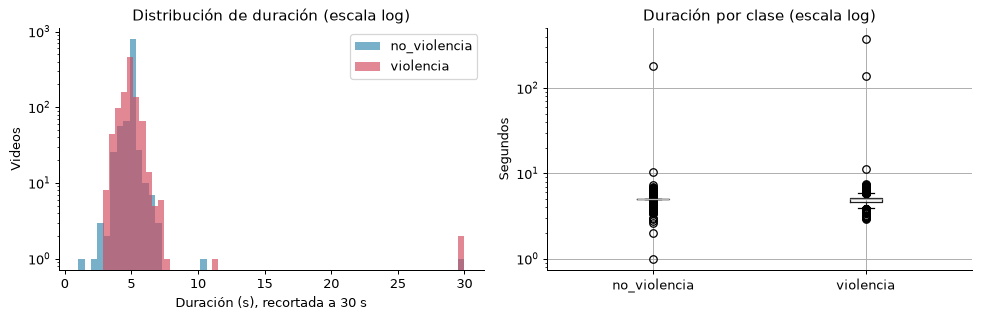


Clips de más de 30 s: 3
  dataset        clase    archivo   segundos
real_life    violencia  V_789.mp4 375.733333
real_life no_violencia NV_992.mp4 179.900000
real_life    violencia  V_398.mp4 136.966667


In [4]:
resumen = meta.groupby(["dataset", "clase"])["segundos"].describe(
    percentiles=[0.5, 0.95]).round(2)
print(resumen.to_string())

fig, ejes = plt.subplots(1, 2, figsize=(11, 3.8))
for clase, g in meta.groupby("clase"):
    # Se recorta a 30 s para ver donde esta la masa de datos.
    ejes[0].hist(g["segundos"].clip(upper=30), bins=60, alpha=0.65,
                 color=COLORES[clase], label=clase)
ejes[0].set_xlabel("Duración (s), recortada a 30 s")
ejes[0].set_ylabel("Videos")
ejes[0].set_yscale("log")
ejes[0].legend()
ejes[0].set_title("Distribución de duración (escala log)")

meta.boxplot(column="segundos", by="clase", ax=ejes[1], showfliers=True)
ejes[1].set_yscale("log")
ejes[1].set_title("Duración por clase (escala log)")
ejes[1].set_xlabel("")
ejes[1].set_ylabel("Segundos")
plt.suptitle("")
plt.tight_layout()
plt.show()

largos = meta[meta["segundos"] > 30][["dataset", "clase", "archivo", "segundos"]]
print(f"\nClips de más de 30 s: {len(largos)}")
print(largos.sort_values("segundos", ascending=False).to_string(index=False))

## 5. FPS, resolución y formato

Las diferencias de fps cambian cuánto tiempo real cubre cada salto entre frames
muestreados; las de resolución importan porque todo se reescala a 224×224.

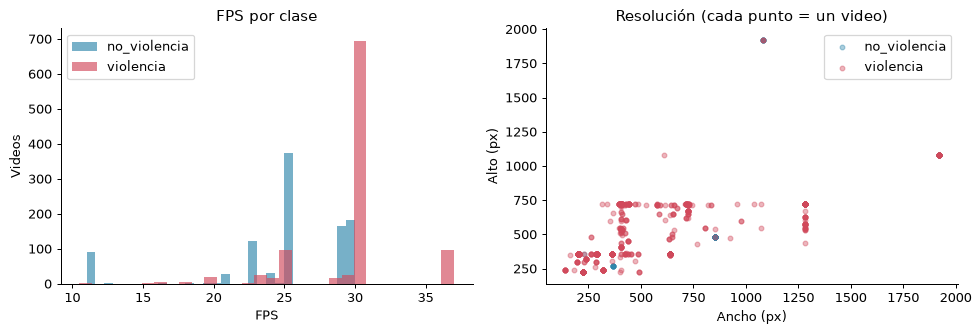

  dataset        clase resolucion  videos
real_life no_violencia    224x224     749
real_life no_violencia   1280x720     115
real_life no_violencia    640x360      79
real_life no_violencia    854x480      35
real_life    violencia    224x224     199
real_life    violencia   1280x720     164
real_life    violencia    640x360     114
real_life    violencia    360x360      49

dataset    clase         formato
real_life  no_violencia  avi          49
                         mp4         951
           violencia     mp4        1000


In [5]:
fig, ejes = plt.subplots(1, 2, figsize=(11, 3.8))

for clase, g in meta.groupby("clase"):
    ejes[0].hist(g["fps"], bins=30, alpha=0.65, color=COLORES[clase], label=clase)
ejes[0].set_xlabel("FPS")
ejes[0].set_ylabel("Videos")
ejes[0].legend()
ejes[0].set_title("FPS por clase")

for clase, g in meta.groupby("clase"):
    ejes[1].scatter(g["ancho"], g["alto"], s=14, alpha=0.4,
                    color=COLORES[clase], label=clase)
ejes[1].set_xlabel("Ancho (px)")
ejes[1].set_ylabel("Alto (px)")
ejes[1].legend()
ejes[1].set_title("Resolución (cada punto = un video)")
plt.tight_layout()
plt.show()

meta["resolucion"] = meta["ancho"].astype(str) + "x" + meta["alto"].astype(str)
top = (meta.groupby(["dataset", "clase", "resolucion"]).size()
       .rename("videos").reset_index()
       .sort_values(["dataset", "clase", "videos"], ascending=[True, True, False])
       .groupby(["dataset", "clase"]).head(4))
print(top.to_string(index=False))
print()
print(meta.groupby(["dataset", "clase", "formato"]).size().to_string())

## 6. Posible atajo: ¿la resolución delata la clase?

Si una característica **que no es el comportamiento** (resolución, fps) separa las
clases, un modelo puede aprenderla en lugar de la pelea. Se mide con la regla más
simple posible: *"si el video mide exactamente 224×224, es no violencia"*.

In [6]:
rl = meta[meta["dataset"] == "real_life"].copy()
es_224 = (rl["ancho"] == 224) & (rl["alto"] == 224)

tabla = pd.crosstab(rl["clase"], es_224.map({True: "224x224", False: "otra resolución"}))
print(tabla.to_string())

# Exactitud de la regla "224x224 -> no_violencia, otra -> violencia".
pred = np.where(es_224, "no_violencia", "violencia")
acc = (pred == rl["clase"]).mean()
print(f"\nExactitud de la regla solo con la resolución: {acc:.1%}")

# Lo mismo con fps: umbral simple a la mediana global.
umbral = rl["fps"].median()
pred_fps = np.where(rl["fps"] > umbral, "violencia", "no_violencia")
print(f"Exactitud de la regla solo con fps > {umbral:.1f}: {(pred_fps == rl['clase']).mean():.1%}")

col_0         224x224  otra resolución
clase                                 
no_violencia      749              251
violencia         199              801

Exactitud de la regla solo con la resolución: 77.5%
Exactitud de la regla solo con fps > 29.0: 81.7%


## 7. Muestra visual

Frame central de 5 videos aleatorios por clase (semilla fija). Sirve para
comprobar a ojo qué hay en cada clase y qué tan distinta es la calidad.

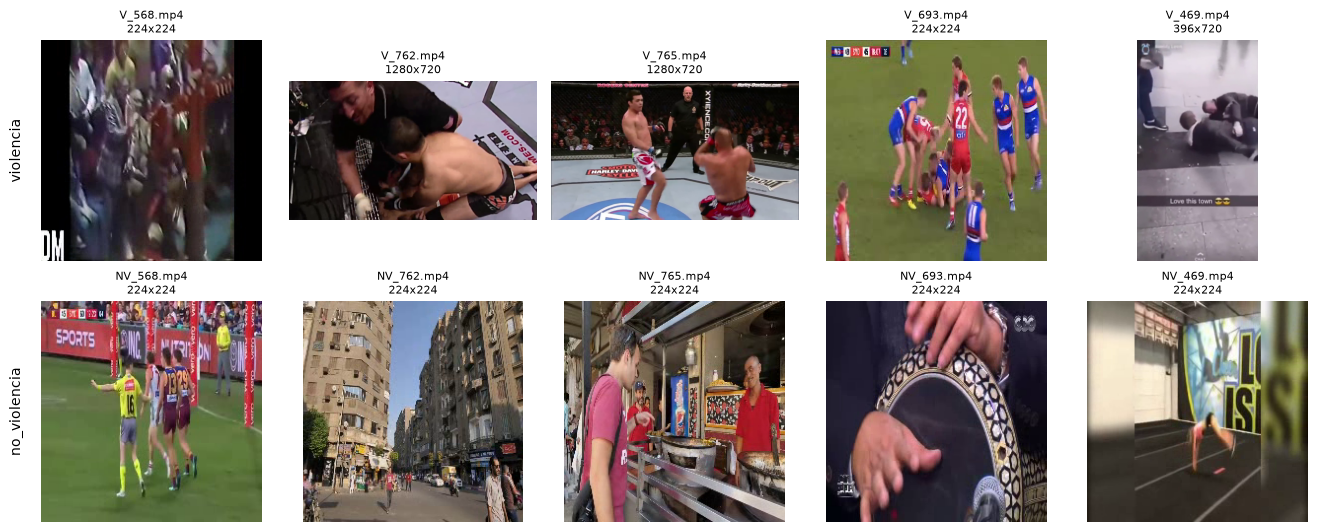

In [7]:
def frame_central(ruta: str) -> np.ndarray:
    """Devuelve el frame del medio del video en RGB."""
    cap = cv2.VideoCapture(ruta)
    cap.set(cv2.CAP_PROP_POS_FRAMES, int(cap.get(cv2.CAP_PROP_FRAME_COUNT)) // 2)
    ok, frame = cap.read()
    cap.release()
    return cv2.cvtColor(frame, cv2.COLOR_BGR2RGB) if ok else np.zeros((224, 224, 3), np.uint8)


N = 5
fig, ejes = plt.subplots(2, N, figsize=(3 * N, 6))
for fila, clase in enumerate(["violencia", "no_violencia"]):
    muestra = rl[rl["clase"] == clase].sample(N, random_state=42)
    for ax, (_, v) in zip(ejes[fila], muestra.iterrows()):
        ax.imshow(frame_central(v["ruta"]))
        ax.set_title(f"{v['archivo']}\n{v['ancho']}x{v['alto']}", fontsize=9)
        ax.axis("off")
    ejes[fila][0].text(-0.08, 0.5, clase, transform=ejes[fila][0].transAxes,
                       rotation=90, va="center", ha="right", fontsize=11)
plt.tight_layout()
plt.show()

## 8. RWF-2000

Esta sección solo corre si `data/raw/rwf2000/` existe en la máquina. Los
videos están en el Drive del grupo (`datasets/rwf2000/RWF-2000`). Según el
registro del equipo, son 2000 clips de 5 s: 800 + 800 en `train` y
200 + 200 en `val`; aquí se contrasta con lo que realmente se lee.

In [8]:
if len(rwf):
    print(rwf.groupby(["split", "clase"]).size().unstack(fill_value=0).to_string())
    print()
    print(rwf.groupby("clase")[["segundos", "fps", "ancho", "alto"]].describe().T.round(2).to_string())
    print("Ilegibles:", int((~rwf["legible"].astype(bool)).sum()))
else:
    print("RWF-2000 no está en esta máquina: descargar de datasets/rwf2000 del "
          "Drive a data/raw/rwf2000/ y volver a ejecutar el notebook.")

RWF-2000 no está en esta máquina: descargar de datasets/rwf2000 del Drive a data/raw/rwf2000/ y volver a ejecutar el notebook.


## 9. Conclusiones (Real Life Violence)

Todo lo siguiente sale de las tablas y figuras de arriba; la sección 8
(RWF-2000) queda pendiente de ejecutarse con los videos locales.

- **Integridad y balance:** 2000 videos, 1000 por clase, 0 ilegibles y 0 vacíos.
  No hace falta ponderar clases para este dataset.
- **Duración:** la mediana es 5 s en ambas clases, parecida a los 5 s de RWF-2000.
  Hay 3 clips de más de 30 s (`V_789` ≈ 376 s, `NV_992` ≈ 180 s, `V_398` ≈ 137 s).
  Con muestreo uniforme de 16 frames, uno de ~6 minutos daría un frame cada ~25 s y
  casi no veríamos movimiento; **hay que decidir en el equipo** si se excluyen o se
  recortan (son 3 de 2000).
- **Atajos posibles:** la clase se puede predecir **sin mirar el contenido**:
  solo con la resolución (224×224 → no violencia) se acierta 77,5 % y solo con
  fps > 29 se acierta 81,7 %. Es decir, parte de lo que el modelo podría aprender de
  este dataset es calidad/origen del video y no comportamiento. Mitigaciones a
  discutir: evaluar siempre también en RWF-2000 (fuente distinta) y reportar
  ambos resultados por separado; revisar si RWF-2000 tiene un sesgo parecido
  cuando se ejecute la sección 8.
- **Formato:** 49 clips `NonViolence` son `.avi` y el resto `.mp4`; OpenCV
  los lee todos, no requiere tratamiento aparte.
- **Relación de aspecto:** hay videos 16:9, cuadrados y verticales (p. ej. 396×720).
  El paso de resize a 224×224 los deforma de distinta manera; es una decisión del
  pipeline a tener en cuenta, no algo que este notebook resuelva.
- **Contenido (muestra de 5 por clase):** aparecen peleas de deporte de contacto
  (artes marciales mixtas, fútbol) y tomas de transmisión, no solo cámaras de
  vigilancia. Coincide con la limitación del plan sobre deportes y confirma que
  RWF-2000 es el dataset más cercano al caso de uso.

La comparación 8 vs 16 vs 32 frames está en `03_comparar_frames.ipynb`.